<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_field_theory/sft_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Field Theory* — `sft_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SFT Ch 1 Figures — Colab Notebook
**Statistical Field Theory · Chapter 1: From Spins to Fields**

PSE Lab · SeoulTech · Tong (Cambridge)

Figures saved to `figures/ch01/`. OUTDIR and save() are defined in each cell independently.

| Figure | Topic | Slide section |
|--------|-------|---------------|
| fig01 | MFT self-consistency, $m(T)$, $m(B)$ | §1.1.2 |
| fig02 | Landau 2nd-order: $F(m)$, $m_0(T)$, $\chi(T)$ | §1.2.1 |
| fig03 | Landau 1st-order: $F(m)$, discontinuous $m$ | §1.2.2 |
| fig04 | Domain wall profile & width/tension vs $T$ | §1.3.2 |
| fig05 | Phase diagram $(T,B)$ & correlation length $\xi$ | §1.3 |

---
## fig01 · MFT Self-Consistency (§1.1–1.2)

**Left**: Graphical solution of $m=\tanh(\beta Jzm)$. **Centre**: $m(T)$ continuous transition. **Right**: Equation of state $m(B)$ with hysteresis.

/tmp/ipykernel_9215/383095109.py:68: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  m_arr = np.array([fsolve(lambda mv: mv - np.tanh((mv+b)*Tc/T), 0.0)[0]
/tmp/ipykernel_9215/383095109.py:68: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  m_arr = np.array([fsolve(lambda mv: mv - np.tanh((mv+b)*Tc/T), 0.0)[0]


  saved -> figures/ch01/fig01_mft_selfconsistency.png


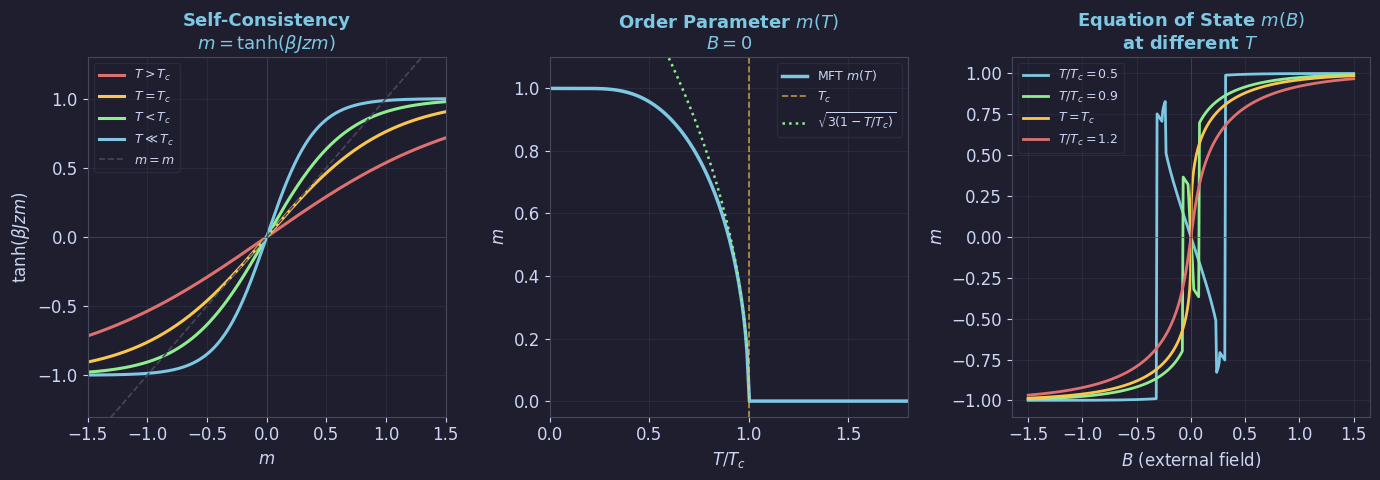

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve, minimize_scalar
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01: MFT Self-Consistency (Ch 1.1-1.2) ──────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
m = np.linspace(-1.5, 1.5, 400)
for bJz, col, lab in [(0.6,RED,r'$T>T_c$'),(1.0,YELLOW,r'$T=T_c$'),
                       (1.5,GREEN,r'$T<T_c$'),(2.5,BLUE,r'$T\ll T_c$')]:
    ax.plot(m, np.tanh(bJz*m), color=col, lw=2.2, label=lab)
ax.plot(m, m, color=EDGE, lw=1.2, ls='--', label=r'$m=m$')
ax.axhline(0,color=EDGE,lw=0.5); ax.axvline(0,color=EDGE,lw=0.5)
ax.set_xlim(-1.5,1.5); ax.set_ylim(-1.3,1.3)
ax.set_xlabel(r'$m$'); ax.set_ylabel(r'$\tanh(\beta Jzm)$')
ax.set_title('Self-Consistency\n'+r'$m=\tanh(\beta Jzm)$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG, loc='upper left'); ax.grid(True)

ax2 = axes[1]
Tc = 1.0; T_arr = np.linspace(0.01, 1.8, 300)
m_sol = np.zeros_like(T_arr)
for i, T in enumerate(T_arr):
    if T >= Tc:
        m_sol[i] = 0.0
    else:
        sol = fsolve(lambda mv: mv - np.tanh(mv*Tc/T), 0.9, full_output=True)
        m_sol[i] = abs(sol[0][0]) if sol[2]==1 else 0.0
ax2.plot(T_arr/Tc, m_sol, color=BLUE, lw=2.5, label=r'MFT $m(T)$')
ax2.axvline(1.0, color=YELLOW, lw=1.2, ls='--', alpha=0.7, label=r'$T_c$')
t_mf = np.linspace(0, 0.99, 200)
ax2.plot(t_mf, np.sqrt(3*(1-t_mf)), color=GREEN, lw=1.8, ls=':',
         label=r'$\sqrt{3(1-T/T_c)}$')
ax2.set_xlabel(r'$T/T_c$'); ax2.set_ylabel(r'$m$')
ax2.set_title(r'Order Parameter $m(T)$'+'\n'+r'$B=0$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0,1.8); ax2.set_ylim(-0.05,1.1)

ax3 = axes[2]
B_arr = np.linspace(-1.5, 1.5, 400)
for T_ratio, col, lab in [(0.5,BLUE,r'$T/T_c=0.5$'),(0.9,GREEN,r'$T/T_c=0.9$'),
                           (1.0,YELLOW,r'$T=T_c$'),(1.2,RED,r'$T/T_c=1.2$')]:
    T = T_ratio * Tc
    m_arr = np.array([fsolve(lambda mv: mv - np.tanh((mv+b)*Tc/T), 0.0)[0]
                      for b in B_arr])
    ax3.plot(B_arr, m_arr, color=col, lw=2.0, label=lab)
ax3.axhline(0,color=EDGE,lw=0.5); ax3.axvline(0,color=EDGE,lw=0.5)
ax3.set_xlabel(r'$B$ (external field)'); ax3.set_ylabel(r'$m$')
ax3.set_title(r'Equation of State $m(B)$'+'\nat different $T$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('fig01_mft_selfconsistency.png', fig)


---
## fig02 · Landau 2nd-order Transition (§1.2.1)

**Left**: $F=a_2m^2+a_4m^4$ developing double-well below $T_c$. **Right**: $m_0\sim(T_c-T)^{1/2}$ and $\chi\sim|T-T_c|^{-1}$.

  saved -> figures/ch01/fig02_landau_2nd_order.png


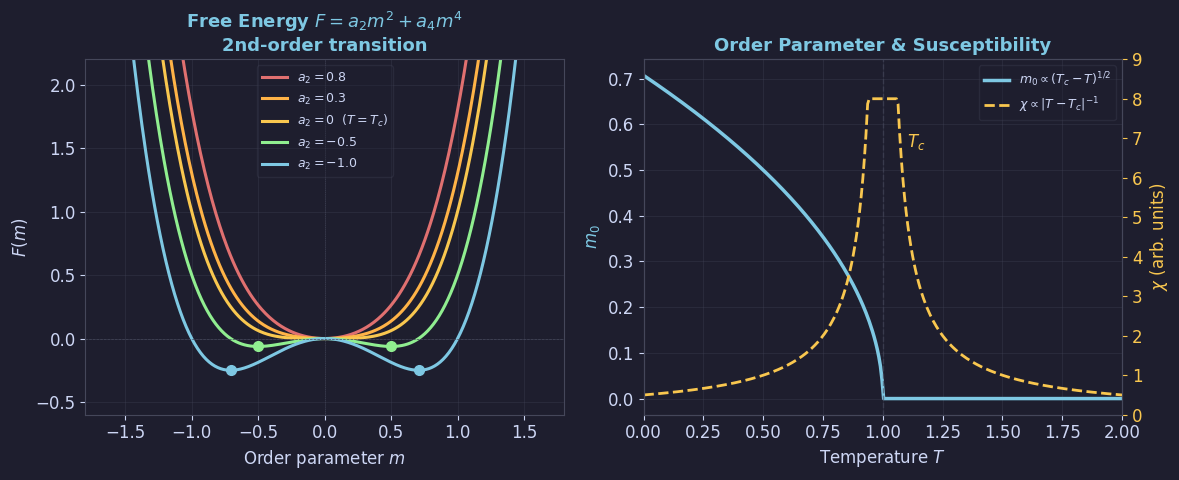

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve, minimize_scalar
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02: Landau 2nd-order (Ch 1.2.1) ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)
m = np.linspace(-1.8, 1.8, 500); a4=1.0

ax = axes[0]
for a2, col, lab in [(0.8,RED,r'$a_2=0.8$'),(0.3,ORANGE,r'$a_2=0.3$'),
                      (0.0,YELLOW,r'$a_2=0$  ($T=T_c$)'),
                      (-0.5,GREEN,r'$a_2=-0.5$'),(-1.0,BLUE,r'$a_2=-1.0$')]:
    F = a2*m**2 + a4*m**4
    ax.plot(m, F, color=col, lw=2.2, label=lab)
    if a2 < 0:
        m0 = np.sqrt(-a2/(2*a4)); F0 = a2*m0**2 + a4*m0**4
        ax.plot([-m0,m0],[F0,F0],'o',color=col,ms=7,zorder=5)
ax.axhline(0,color=EDGE,lw=0.5,ls='--'); ax.axvline(0,color=EDGE,lw=0.5,ls=':')
ax.set_xlim(-1.8,1.8); ax.set_ylim(-0.6,2.2)
ax.set_xlabel(r'Order parameter $m$'); ax.set_ylabel(r'$F(m)$')
ax.set_title(r'Free Energy $F=a_2m^2+a_4m^4$'+'\n2nd-order transition', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG, loc='upper center'); ax.grid(True)

ax2 = axes[1]
Tc=1.0; t_arr = np.linspace(-1.0,1.0,300)
m0_arr = np.where(t_arr<0, np.sqrt(np.abs(t_arr)/(2*a4)), 0.0)
chi = np.where(t_arr!=0, 0.5/np.abs(t_arr), 8.0); chi = np.minimum(chi,8)
ax2.plot(t_arr+Tc, m0_arr, color=BLUE, lw=2.5, label=r'$m_0\propto(T_c-T)^{1/2}$')
ax2_r = ax2.twinx()
ax2_r.plot(t_arr+Tc, chi, color=YELLOW, lw=2.0, ls='--',
           label=r'$\chi\propto|T-T_c|^{-1}$')
ax2_r.set_ylabel(r'$\chi$ (arb. units)', color=YELLOW)
ax2_r.tick_params(colors=YELLOW); ax2_r.set_ylim(0,9)
ax2.axvline(Tc, color=EDGE, lw=1.0, ls='--', alpha=0.6)
ax2.text(Tc+0.1, 0.55, r'$T_c$', color=YELLOW, fontsize=12)
ax2.set_xlabel(r'Temperature $T$'); ax2.set_ylabel(r'$m_0$', color=BLUE)
ax2.set_title('Order Parameter & Susceptibility', color=BLUE)
l1,lb1=ax2.get_legend_handles_labels(); l2,lb2=ax2_r.get_legend_handles_labels()
ax2.legend(l1+l2, lb1+lb2, fontsize=9, labelcolor=FG, loc='upper right')
ax2.grid(True); ax2.set_xlim(0,2.0)

plt.tight_layout(pad=1.2)
save('fig02_landau_2nd_order.png', fig)


---
## fig03 · Landau 1st-order Transition (§1.2.2)

**Left**: $F=a_2m^2+a_4m^4+a_6m^6$ with $a_4<0$ — metastable states. **Right**: Discontinuous jump in $m$ at $T_1$.

  saved -> figures/ch01/fig03_landau_1st_order.png


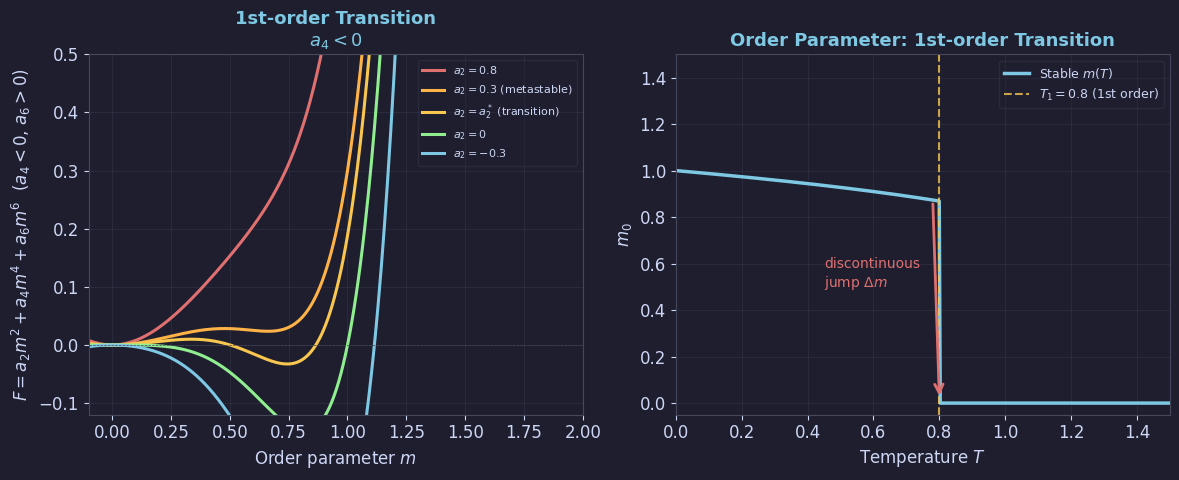

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve, minimize_scalar
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03: Landau 1st-order (Ch 1.2.2) ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)
m = np.linspace(-0.3,2.0,500); a4_neg=-1.0; a6=1.0

ax = axes[0]
for a2, col, lab in [(0.8,RED,r'$a_2=0.8$'),(0.3,ORANGE,r'$a_2=0.3$ (metastable)'),
                      (0.188,YELLOW,r'$a_2=a_2^*$ (transition)'),
                      (0.0,GREEN,r'$a_2=0$'),(-0.3,BLUE,r'$a_2=-0.3$')]:
    F = a2*m**2 + a4_neg*m**4 + a6*m**6
    ax.plot(m, F, color=col, lw=2.2, label=lab)
ax.axhline(0,color=EDGE,lw=0.5,ls='--')
ax.set_xlim(-0.1,2.0); ax.set_ylim(-0.12,0.5)
ax.set_xlabel(r'Order parameter $m$')
ax.set_ylabel(r'$F=a_2m^2+a_4m^4+a_6m^6$  ($a_4<0$, $a_6>0$)')
ax.set_title('1st-order Transition\n'+r'$a_4<0$', color=BLUE)
ax.legend(fontsize=8, labelcolor=FG); ax.grid(True)

ax2 = axes[1]
T_vals = np.linspace(0,1.5,500); m_stab=np.zeros_like(T_vals); T1=0.8
for i,T in enumerate(T_vals):
    a2=T-1.0
    if T>T1: m_stab[i]=0.0
    else:
        res=minimize_scalar(lambda mm: a2*mm**2+a4_neg*mm**4+a6*mm**6,
                            bounds=(0.1,1.8), method='bounded')
        m_stab[i]=res.x if res.fun<0 else 0.0
ax2.plot(T_vals, m_stab, color=BLUE, lw=2.5, label=r'Stable $m(T)$')
ax2.axvline(T1, color=YELLOW, lw=1.5, ls='--', alpha=0.8,
            label=f'$T_1={T1}$ (1st order)')
m_jump=m_stab[T_vals<T1][-1]
ax2.annotate('', xy=(T1,0.02), xytext=(T1-0.02,m_jump),
             arrowprops=dict(arrowstyle='->',color=RED,lw=2.0,mutation_scale=15))
ax2.text(T1-0.35,0.5,'discontinuous\njump $\\Delta m$',color=RED,fontsize=10)
ax2.set_xlabel(r'Temperature $T$'); ax2.set_ylabel(r'$m_0$')
ax2.set_title('Order Parameter: 1st-order Transition', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0,1.5); ax2.set_ylim(-0.05,1.5)

plt.tight_layout(pad=1.2)
save('fig03_landau_1st_order.png', fig)


---
## fig04 · Domain Wall Profile (§1.3.2)

**Left**: $m(x)=m_0\tanh(x/\xi)$ for various $\xi$. **Right**: Wall width $\xi\to\infty$ and tension $\sigma\to0$ as $T\to T_c$.

  saved -> figures/ch01/fig04_domain_wall.png


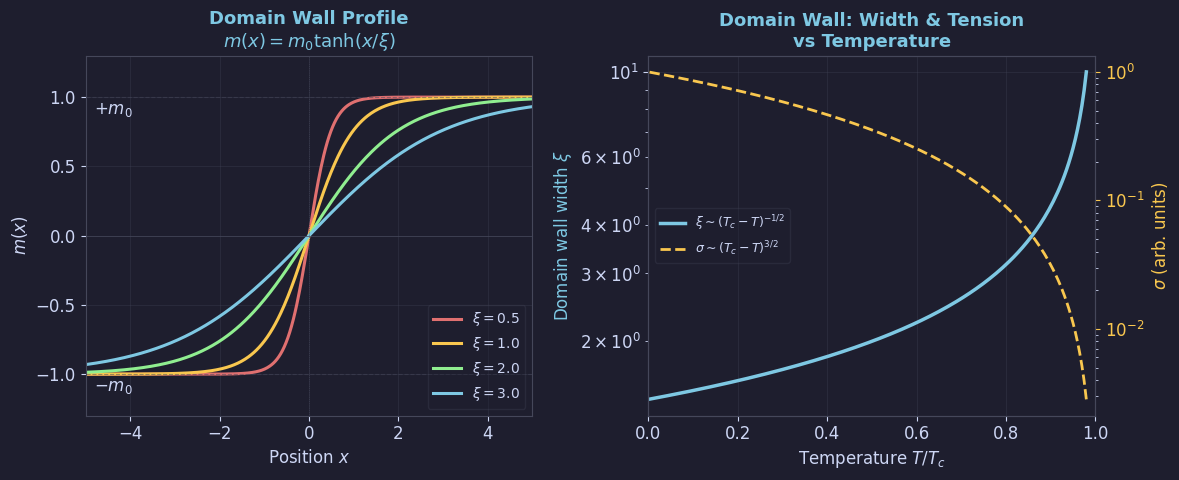

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve, minimize_scalar
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04: Domain Wall (Ch 1.3.2) ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)
x = np.linspace(-5,5,500)

ax = axes[0]
for xi,col,lab in [(0.5,RED,r'$\xi=0.5$'),(1.0,YELLOW,r'$\xi=1.0$'),
                    (2.0,GREEN,r'$\xi=2.0$'),(3.0,BLUE,r'$\xi=3.0$')]:
    ax.plot(x, np.tanh(x/xi), color=col, lw=2.2, label=lab)
ax.axhline(1.0,color=EDGE,lw=0.8,ls='--',alpha=0.5)
ax.axhline(-1.0,color=EDGE,lw=0.8,ls='--',alpha=0.5)
ax.axhline(0,color=EDGE,lw=0.5); ax.axvline(0,color=EDGE,lw=0.5,ls=':')
ax.text(-4.8,0.88,r'$+m_0$',color=FG,fontsize=12)
ax.text(-4.8,-1.12,r'$-m_0$',color=FG,fontsize=12)
ax.set_xlabel(r'Position $x$'); ax.set_ylabel(r'$m(x)$')
ax.set_title(r'Domain Wall Profile'+'\n'+r'$m(x)=m_0\tanh(x/\xi)$', color=BLUE)
ax.legend(fontsize=10, labelcolor=FG); ax.grid(True)
ax.set_xlim(-5,5); ax.set_ylim(-1.3,1.3)

ax2 = axes[1]
t_arr = np.linspace(0.02,1.0,200)
xi_arr = np.sqrt(2.0/t_arr)
sigma_arr = t_arr**(1.5)
l1, = ax2.semilogy(1-t_arr, xi_arr, color=BLUE, lw=2.5,
                    label=r'$\xi\sim(T_c-T)^{-1/2}$')
ax2_r = ax2.twinx()
l2, = ax2_r.semilogy(1-t_arr, sigma_arr, color=YELLOW, lw=2.0, ls='--',
                      label=r'$\sigma\sim(T_c-T)^{3/2}$')
ax2_r.set_ylabel(r'$\sigma$ (arb. units)', color=YELLOW)
ax2_r.tick_params(colors=YELLOW)
ax2.set_xlabel(r'Temperature $T/T_c$')
ax2.set_ylabel(r'Domain wall width $\xi$', color=BLUE)
ax2.set_title('Domain Wall: Width & Tension\nvs Temperature', color=BLUE)
ax2.legend(handles=[l1,l2], fontsize=9, labelcolor=FG, loc='center left')
ax2.grid(True); ax2.set_xlim(0,1.0)

plt.tight_layout(pad=1.2)
save('fig04_domain_wall.png', fig)


---
## fig05 · Phase Diagram & Correlation Length (§1.3)

**Left**: $(T,B)$ Ising phase diagram with critical point. **Right**: $\xi\sim|T-T_c|^{-\nu}$ for MFT, 3D, 2D Ising.

  saved -> figures/ch01/fig05_phase_diagram.png


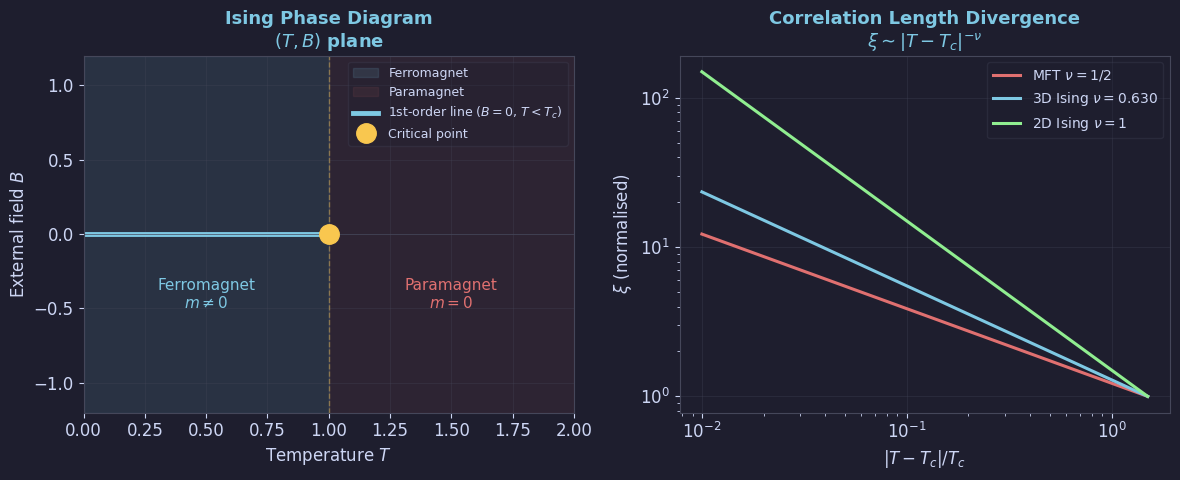

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve, minimize_scalar
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05: Phase Diagram (Ch 1 Summary) ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]; Tc=1.0
ax.fill_between([0,Tc],[-1.2,-1.2],[1.2,1.2], color=BLUE, alpha=0.12,
                label='Ferromagnet')
ax.fill_between([Tc,2.0],[-1.2,-1.2],[1.2,1.2], color=RED, alpha=0.08,
                label='Paramagnet')
ax.plot([0,Tc],[0,0], color=BLUE, lw=3.5, label=r'1st-order line ($B=0$, $T<T_c$)')
ax.plot([Tc],[0],'o', color=YELLOW, ms=14, zorder=5, label='Critical point')
ax.axvline(Tc, color=YELLOW, lw=1.0, ls='--', alpha=0.4)
ax.text(0.5*Tc, -0.5, 'Ferromagnet\n'+r'$m\neq0$', color=BLUE, fontsize=11, ha='center')
ax.text(1.5*Tc, -0.5, 'Paramagnet\n$m=0$', color=RED, fontsize=11, ha='center')
ax.set_xlabel(r'Temperature $T$'); ax.set_ylabel(r'External field $B$')
ax.set_title('Ising Phase Diagram\n'+r'$(T,B)$ plane', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax.set_xlim(0,2.0); ax.set_ylim(-1.2,1.2); ax.axhline(0,color=EDGE,lw=0.5)
ax.grid(True)

ax2 = axes[1]
t_arr = np.linspace(0.01,1.5,300)
for nu,col,lab in [(0.5,RED,r'MFT $\nu=1/2$'),
                    (0.630,BLUE,r'3D Ising $\nu=0.630$'),
                    (1.0,GREEN,r'2D Ising $\nu=1$')]:
    xi = t_arr**(-nu); xi /= xi[-1]
    ax2.loglog(t_arr, xi, color=col, lw=2.2, label=lab)
ax2.set_xlabel(r'$|T-T_c|/T_c$'); ax2.set_ylabel(r'$\xi$ (normalised)')
ax2.set_title(r'Correlation Length Divergence'+'\n'+r'$\xi\sim|T-T_c|^{-\nu}$',
              color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)

plt.tight_layout(pad=1.2)
save('fig05_phase_diagram.png', fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/ch01'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) \
        if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')

zip_name = 'sft_ch01_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 5 figures:
  fig01_mft_selfconsistency.png  (208 KB)
  fig02_landau_2nd_order.png  (218 KB)
  fig03_landau_1st_order.png  (162 KB)
  fig04_domain_wall.png  (174 KB)
  fig05_phase_diagram.png  (155 KB)
Zip: sft_ch01_figures.zip  (874 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>